calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object m

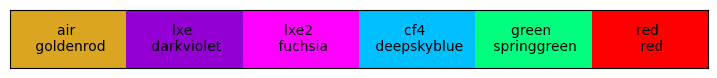

In [1]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors()

rad2deg = 180/np.pi

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


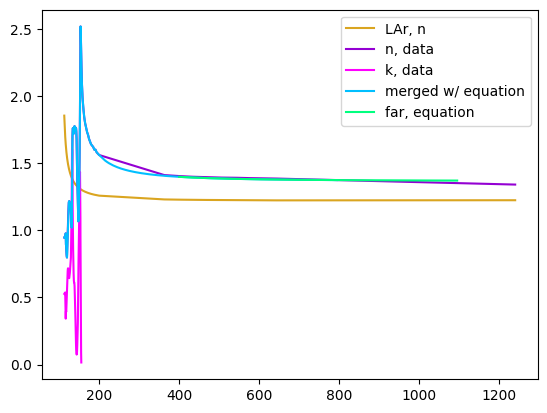

In [2]:
# LXe data

from nobleFunctions import *
rho_lxe = density_t(273-110)
wlen_n_far = np.arange(400, 1100, 5)
lxe_n_Far = n_index_rho(lamb = wlen_n_far, rho = rho_lxe)

## Load in LXe data
xe_n_xeV, xe_n_y = np.loadtxt(os.path.join(OPTICS_DATA_PATH, "LXe-n_vs_Ephoton.txt"), delimiter=",", skiprows=0, unpack = True)
xe_k_xeV, xe_k_y = np.loadtxt(os.path.join(OPTICS_DATA_PATH, "LXe-k_vs_Ephoton.txt"), delimiter=",", skiprows=0, unpack = True)
lxe_wlen_merged, lxe_n_merged = np.loadtxt(os.path.join(OPTICS_DATA_PATH, "lxe_n_merged.txt"), delimiter="\t", skiprows=0, unpack = True)

wlen_lxe_n = 1240/xe_n_xeV
wlen_lxe_k = 1240/xe_k_xeV

lar_n_all = ODL.OpticsData().LArIndex(wlen_lxe_n)
plt.plot(wlen_lxe_n, lar_n_all, label = "LAr, n")

plt.plot(wlen_lxe_n, xe_n_y, label="n, data")
plt.plot(wlen_lxe_k, xe_k_y, label="k, data")

plt.plot(lxe_wlen_merged, lxe_n_merged, label="merged w/ equation")
plt.plot(wlen_n_far, lxe_n_Far, label="far, equation")

plt.legend()
plt.show()

---
## Snell's law for incoming photons - Vacuum
(sanity check vs other work in vacuum)

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/828557558.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  Z[i, j] = PhotonInfo(wavelength, angle).theta_3 * rad2deg


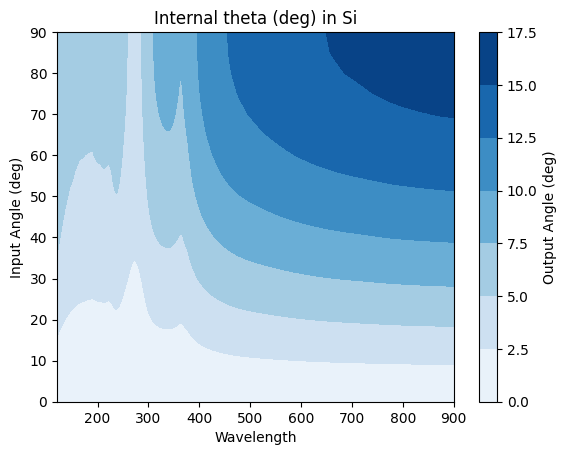

In [3]:
# Define the range of X and Y
X = np.arange(120, 901, 2.5)
Y = np.arange(0, 91, 5)

# Calculate Z
Z = np.zeros((len(Y), len(X)))
for i, angle in enumerate(Y):
    for j, wavelength in enumerate(X):
        # Calculate Z value based on your calculation
        Z[i, j] = PhotonInfo(wavelength, angle).theta_3 * rad2deg

# Create a meshgrid for X and Y
X, Y = np.meshgrid(X, Y)

# Create the contour plot
plt.contourf(X, Y, Z, cmap='Blues', levels = 7)

# Set labels and title
plt.xlabel('Wavelength')
plt.ylabel('Input Angle (deg)')
plt.title('Internal theta (deg) in Si')

# Show the plot
plt.colorbar(label='Output Angle (deg)')
plt.show()


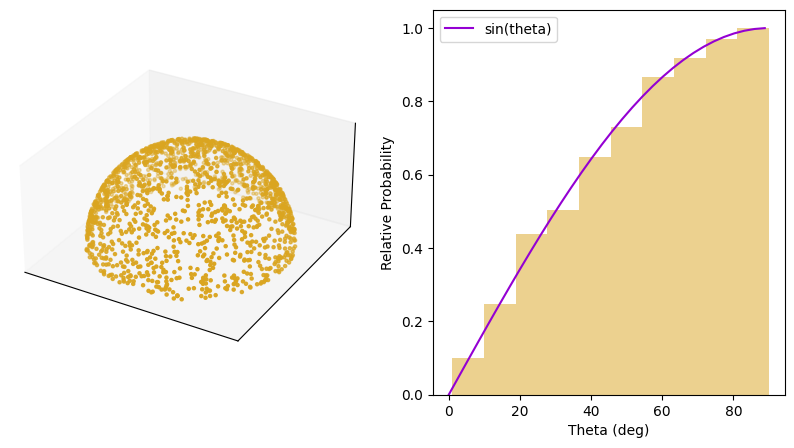

In [ ]:
num_points = 5000

phi = 2 * np.pi * np.random.rand(num_points)

# Sample cos(theta) uniformly from [0, 1]
cos_theta = np.random.rand(num_points)

# Compute theta from cos(theta)
theta = np.arccos(cos_theta)

# Now (theta, phi) are the spherical coordinates of num_points points
# uniformly distributed on the surface of the sphere

# import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Convert spherical coordinates to Cartesian coordinates
x = np.sin(theta) * np.cos(phi)
y = np.sin(theta) * np.sin(phi)
z = np.cos(theta)

# Create a 3D plot
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

ax1.scatter(x[::3], y[::3], z[::3], marker='.')

# Set equal aspect ratio
ax1.set_box_aspect([1,1,0.5])
ax1.set_zticks([])
ax1.set_xticks([])
ax1.set_yticks([])
# ax1.set_frame_on(False)

# ax2.hist(theta*180/np.pi, bins=20, density=True, histtype='step')

counts, bins = np.histogram(theta*180/np.pi, bins=10, density=True)
counts = counts / counts.max()
ax2.hist(bins[:-1], bins, weights=counts, histtype='stepfilled', alpha=0.5)

xtheta = np.arange(0, np.pi/2, 0.05)
ax2.plot(xtheta * 180/np.pi, np.sin(xtheta), label="sin(theta)")
ax2.legend()

ax2.set_xlabel("Theta (deg)")
ax2.set_ylabel("Relative Probability")


plt.show()

### Exiting photons (eXT)

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
<class 'PDEModel.OpticsDataLoader.OpticsData'>


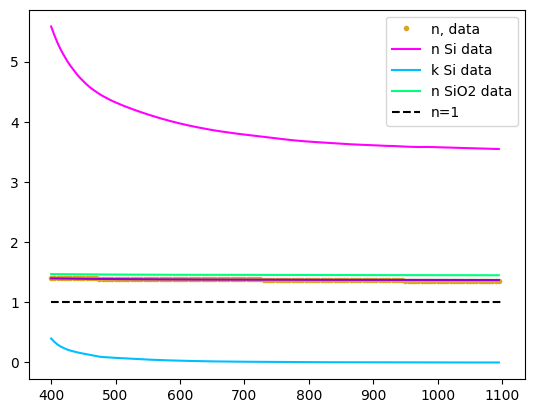

In [4]:
wlen_ext = np.arange(400, 1100, 5)

finterp_lxe_n = interp1d(wlen_lxe_n, xe_n_y, kind='linear')
finterp_lar_n = lambda wlen: np.where(np.asarray(wlen) > 890, ODL.OpticsData().LArIndex(890), ODL.OpticsData().LArIndex(wlen))
fAir = lambda wlen: 1

medium = fAir
lxe_n_data = finterp_lxe_n(wlen_ext)
# medium = finterp_lxe_n

plt.plot(wlen_ext, lxe_n_data, ".", label="n, data")
plt.plot(wlen_ext, n_index_rho(lamb = wlen_ext, rho = rho_lxe))

dataAspnes = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH,"GoodMerged/silicon_merged_AspnesMiddle.txt"))

print(type(dataAspnes))

plt.plot(wlen_ext, np.real(dataAspnes.SiIndex(wlen_ext)), label="n Si data")
plt.plot(wlen_ext, np.imag(dataAspnes.SiIndex(wlen_ext)), label="k Si data")

plt.plot(wlen_ext, np.real(dataAspnes.OxideIndex(wlen_ext)), label="n SiO2 data")
# plt.plot(wlen_ext, np.imag(data.OxideIndex(wlen_ext)), label="k SiO2 data")

plt.hlines(1, 400, 1100, colors='k', linestyles='dashed', label="n=1")

# plt.yscale("log")
plt.legend()
plt.show()

In [5]:
# theta 1 is now inside the Si
angleStep = 2.5
theta1_vals = np.logspace(np.log10(0.1), np.log10(89), 100)
tOxide = 18
wlenTest = 600

theta3 = []
# extPhoton
for theta in theta1_vals:
    extPhoton = PhotonInfo(wlen=wlenTest, theta_1=theta, dataHelper = dataAspnes)
    
    # swap the n values for outside the Si
    # extPhoton.nVacuum = dataAspnes.SiIndex(wlen_ext)
    extPhoton.nVacuum = extPhoton.nSi
    extPhoton.nSi = medium(wlenTest)
    
    # print(extPhoton.nVacuum, extPhoton.nSi)

    extPhoton.BuildThetas()
    theta3.append(extPhoton.theta_3 * rad2deg)
    # print(extPhoton.theta_3)
    
    # Trans_angle = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)



/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


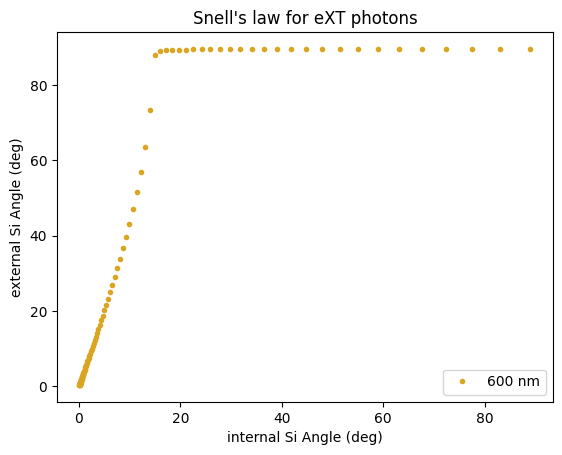

In [6]:
plt.plot(theta1_vals, theta3, ".", label = f"{wlenTest} nm")

plt.title("Snell's law for eXT photons")
plt.xlabel("internal Si Angle (deg)")
plt.ylabel("external Si Angle (deg)")

plt.legend()
plt.show()

(5.581900000000001+0.39750400000000036j)
1
(3.9705280000000003+0.029648000000000008j)
1
(3.669244+0.0052640000000000004j)
1
(3.575108+0.0005j)
1


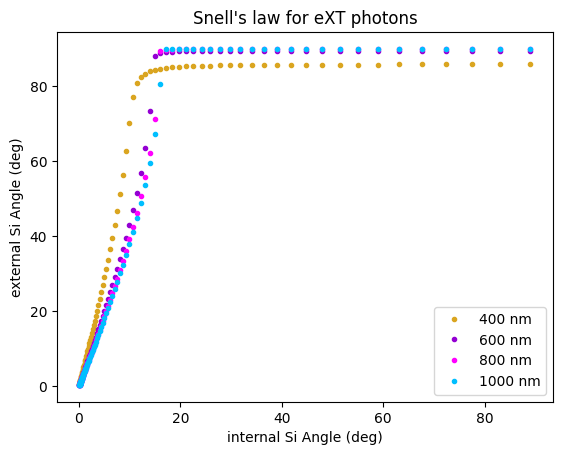

In [7]:
# Define the range of X and Y
X = wlen_ext
X = [400, 600, 800, 1000]
Y = theta1_vals

extPhoton = PhotonInfo(wlen=X, theta_1=0, dataHelper = dataAspnes)
extPhoton.nVacuum = extPhoton.nSi # swap n values
extPhoton.nSi = medium(X)

for wlen in X:
    extPhoton = PhotonInfo(wlen=wlen, theta_1=theta1_vals, dataHelper = dataAspnes)
    extPhoton.nVacuum = extPhoton.nSi # swap n values
    extPhoton.nSi = medium(wlen)
    print(extPhoton.nVacuum)
    print(extPhoton.nSi)
    
    extPhoton.BuildThetas()
    plt.plot(theta1_vals, extPhoton.theta_3 * rad2deg, ".", label = f"{wlen} nm")
    
plt.title("Snell's law for eXT photons")
plt.xlabel("internal Si Angle (deg)")
plt.ylabel("external Si Angle (deg)")

plt.legend()
plt.show()

In [8]:
wlen_ext = np.arange(400, 1000, 20)
# theta1_vals = np.logspace(np.log10(0.1), np.log10(45), 100)
theta1_vals = np.arange(0, 90, 0.5)

yieldFunction = lambda x: (x-400)/(1000-400)

In [9]:
## all figure for air (or whatever 'medium' function is)
Z = np.zeros((len(theta1_vals), len(wlen_ext))) # snells law
Z_trans = np.zeros((len(theta1_vals), len(wlen_ext))) # transmission and internal angle
Z_transformed = np.zeros((len(theta1_vals), len(wlen_ext))) # tranmission vs external angle
Z_transAndConvolved = np.zeros((len(theta1_vals), len(wlen_ext))) # convolved with yield
Z_trans_and_sinTheta = np.zeros((len(theta1_vals), len(wlen_ext))) # and scaled by sin(theta1) for angular phase space

extPhoton = PhotonInfo(wlen=wlen_ext, theta_1=0, dataHelper = dataAspnes)
extPhoton.nVacuum = extPhoton.nSi # swap n values
extPhoton.nSi = medium(wlen_ext)

for i, angle in enumerate(theta1_vals):
    extPhoton.theta_1 = angle /rad2deg
    extPhoton.BuildThetas()
    
    outsideThetas = np.real(extPhoton.theta_3 * rad2deg)
    Z[i, :] = outsideThetas
    Z_trans[i, :] = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)

### External Photons
## doing the 'transformed' external emission probability
for i, angle in enumerate(theta1_vals):
    for j, wlen in enumerate(wlen_ext):
        
        # first do photon as incoming into Si, to get internal theta1
        extPhoton = PhotonInfo(wlen=wlen, theta_1=angle, dataHelper = dataAspnes)
        extPhoton.nVacuum = medium(wlen) # swap n values
        extPhoton.BuildThetas()
        correspondingTheta1 = np.real(extPhoton.theta_3 * rad2deg) # this is theta1 inside Si (of that outside photon)
        
        # now do that equivalent photon coming out of Si
        extPhoton = PhotonInfo(wlen=wlen, theta_1=correspondingTheta1, dataHelper = dataAspnes)
        extPhoton.nVacuum = extPhoton.nSi # swap n values
        extPhoton.nSi = medium(wlen)
        extPhoton.BuildThetas()
        theta3 = np.real(extPhoton.theta_3 * rad2deg)
        Transmission = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)
        
        Z_transformed[i, j] = Transmission
        
        conv = yieldFunction(wlen) * Transmission
        Z_transAndConvolved[i, j] = conv
        
        Z_trans_and_sinTheta[i, j] = conv * np.sin(correspondingTheta1 / rad2deg)

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/4193059575.py:18: ComplexWarning: Casting complex values to real discards the imaginary part
  Z_trans[i, :] = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/4193059575.py:39: ComplexWarning: Casting complex values to real discards the imaginary part
  Z_transformed[i, j] = Transmission
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/4193059575.py:42: ComplexWarning: Casting complex values to real discards the imaginary part
  Z_transAndConvolved[i, j] = conv
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/4193059575.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  Z_trans_and_sinTheta[i, j] = conv * np.sin(correspondingTheta1 / rad2deg)
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/4193059575.py:39: ComplexWarning: Casting complex values to real discards the imagin

In [10]:
## final figure for LXe
Z_snells_LXe = np.zeros((len(theta1_vals), len(wlen_ext))) # snells law
Z_trans_LXe = np.zeros((len(theta1_vals), len(wlen_ext))) # transmission and internal angle
Z_trans_and_sinTheta_LXe = np.zeros((len(theta1_vals), len(wlen_ext))) # and scaled by sin(theta1) for angular phase space

# swap photon direction (via n vals)
extPhoton = PhotonInfo(wlen=wlen_ext, theta_1=0, dataHelper = dataAspnes)
extPhoton.nVacuum = extPhoton.nSi # swap n values
extPhoton.nSi = finterp_lxe_n(wlen_ext)

for i, angle in enumerate(theta1_vals):
    extPhoton.theta_1 = angle /rad2deg
    extPhoton.BuildThetas()
    
    outsideThetas = np.real(extPhoton.theta_3 * rad2deg)
    Z_snells_LXe[i, :] = outsideThetas
    Z_trans_LXe[i, :] = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)

### External Photons
## doing the 'transformed' external emission probability
for i, angle in enumerate(theta1_vals):
    for j, wlen in enumerate(wlen_ext):
        
        # first do photon as incoming into Si, to get internal theta1
        extPhoton = PhotonInfo(wlen=wlen, theta_1=angle, dataHelper = dataAspnes)
        extPhoton.nVacuum = finterp_lxe_n(wlen)
        extPhoton.BuildThetas()
        correspondingTheta1 = np.real(extPhoton.theta_3 * rad2deg) # this is theta1 inside Si (of that outside photon)
        
        # now do that equivalent photon coming out of Si
        extPhoton = PhotonInfo(wlen=wlen, theta_1=correspondingTheta1, dataHelper = dataAspnes)
        extPhoton.nVacuum = extPhoton.nSi # swap n values
        extPhoton.nSi = finterp_lxe_n(wlen)
        extPhoton.BuildThetas()
        theta3 = np.real(extPhoton.theta_3 * rad2deg)
        Transmission = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)
        
        conv = yieldFunction(wlen) * Transmission
        Z_trans_and_sinTheta_LXe[i, j] = conv * np.sin(correspondingTheta1 / rad2deg)

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/2611056027.py:17: ComplexWarning: Casting complex values to real discards the imaginary part
  Z_trans_LXe[i, :] = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/2611056027.py:39: ComplexWarning: Casting complex values to real discards the imaginary part
  Z_trans_and_sinTheta_LXe[i, j] = conv * np.sin(correspondingTheta1 / rad2deg)


In [11]:
## final figure for LAr
Z_snells_LAr = np.zeros((len(theta1_vals), len(wlen_ext))) # snells law
Z_trans_LAr = np.zeros((len(theta1_vals), len(wlen_ext))) # transmission and internal angle
Z_trans_and_sinTheta_LAr = np.zeros((len(theta1_vals), len(wlen_ext))) # and scaled by sin(theta1) for angular phase space

# swap photon direction (via n vals)
extPhoton = PhotonInfo(wlen=wlen_ext, theta_1=0, dataHelper = dataAspnes)
extPhoton.nVacuum = extPhoton.nSi # swap n values
extPhoton.nSi = finterp_lar_n(wlen_ext)

for i, angle in enumerate(theta1_vals):
    extPhoton.theta_1 = angle /rad2deg
    extPhoton.BuildThetas()
    
    outsideThetas = np.real(extPhoton.theta_3 * rad2deg)
    Z_snells_LAr[i, :] = outsideThetas
    Z_trans_LAr[i, :] = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)

### External Photons
## doing the 'transformed' external emission probability
for i, angle in enumerate(theta1_vals):
    for j, wlen in enumerate(wlen_ext):
        
        # first do photon as incoming into Si, to get internal theta1
        extPhoton = PhotonInfo(wlen=wlen, theta_1=angle, dataHelper = dataAspnes)
        extPhoton.nVacuum = finterp_lar_n(wlen)
        extPhoton.BuildThetas()
        correspondingTheta1 = np.real(extPhoton.theta_3 * rad2deg) # this is theta1 inside Si (of that outside photon)
        
        # now do that equivalent photon coming out of Si
        extPhoton = PhotonInfo(wlen=wlen, theta_1=correspondingTheta1, dataHelper = dataAspnes)
        extPhoton.nVacuum = extPhoton.nSi # swap n values
        extPhoton.nSi = finterp_lar_n(wlen)
        extPhoton.BuildThetas()
        theta3 = np.real(extPhoton.theta_3 * rad2deg)
        Transmission = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)
        
        conv = yieldFunction(wlen) * Transmission
        Z_trans_and_sinTheta_LAr[i, j] = conv * np.sin(correspondingTheta1 / rad2deg)

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/2898086064.py:17: ComplexWarning: Casting complex values to real discards the imaginary part
  Z_trans_LAr[i, :] = extPhoton.Wave_TotalTransmission(thick_oxide=tOxide)
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_83991/2898086064.py:39: ComplexWarning: Casting complex values to real discards the imaginary part
  Z_trans_and_sinTheta_LAr[i, j] = conv * np.sin(correspondingTheta1 / rad2deg)


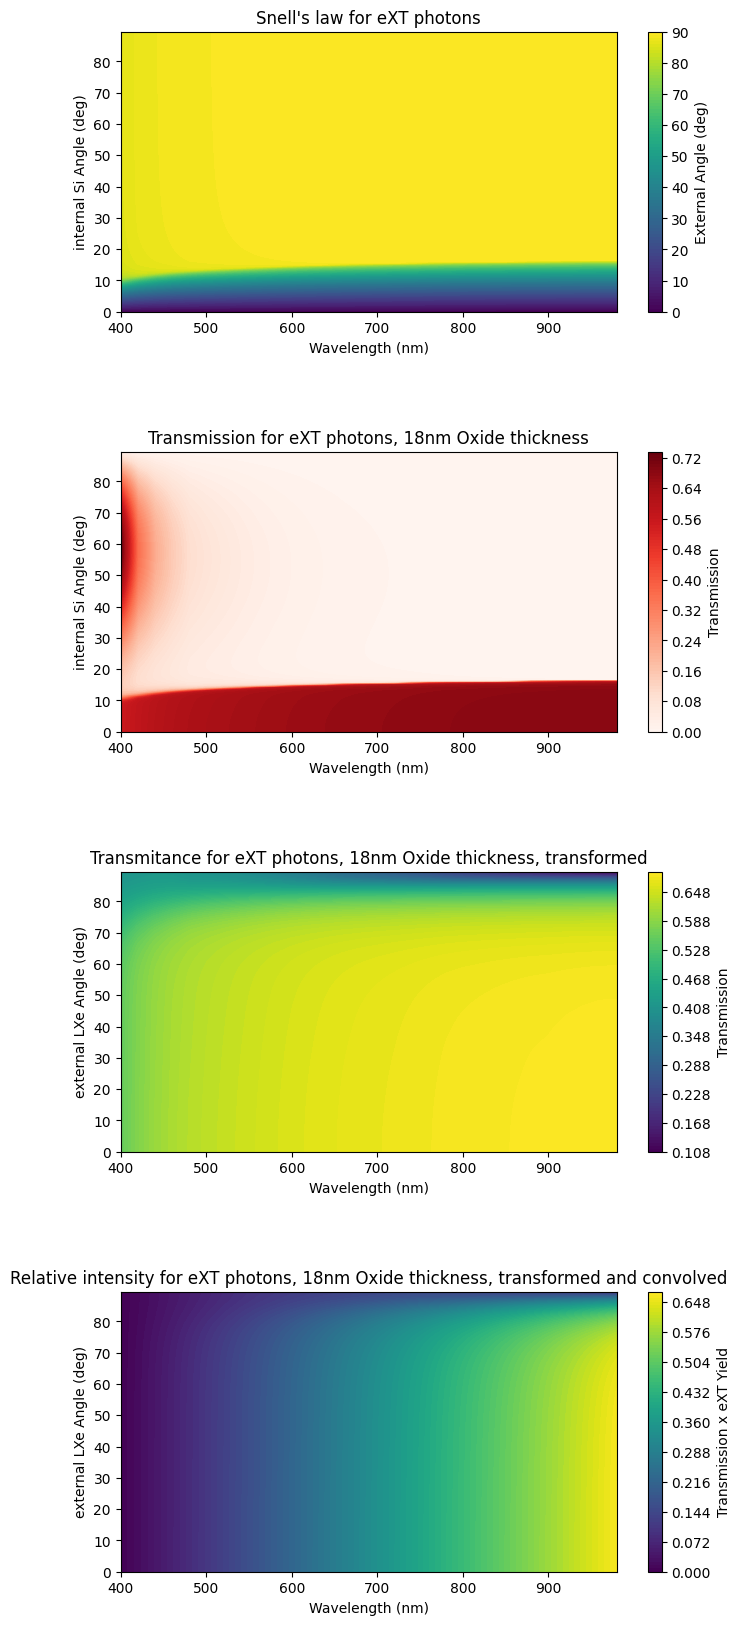

In [12]:
# Create a meshgrid for X and Y
# %matplotlib widget
X, Y = np.meshgrid(wlen_ext, theta1_vals)

### Plotting 
from matplotlib.colors import LogNorm
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(8, 20))

c1 = ax1.contourf(X, Y, Z, levels = 100, cmap='viridis')
fig.colorbar(c1, label='External Angle (deg)', ax=ax1)
ax1.set_title("Snell's law for eXT photons")
ax1.set_xlabel("Wavelength (nm)")
ax1.set_ylabel("internal Si Angle (deg)")

# ax1.set_xlim(790, 810)
# ax1.set_ylim(14, 15.5)

c2 = ax2.contourf(X, Y, Z_trans, levels=100, cmap='Reds')
fig.colorbar(c2, label='Transmission', ax=ax2)
ax2.set_title("Transmission for eXT photons, 18nm Oxide thickness")
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("internal Si Angle (deg)")

c3 = ax3.contourf(X, Y, Z_transformed, levels = 100, cmap='viridis')
fig.colorbar(c3, label='Transmission', ax=ax3)
ax3.set_xlabel("Wavelength (nm)")
ax3.set_ylabel("external LXe Angle (deg)")
ax3.set_title("Transmitance for eXT photons, 18nm Oxide thickness, transformed")

c4 = ax4.contourf(X, Y, Z_transAndConvolved, levels = 100, cmap='viridis')
fig.colorbar(c4, label='Transmission x eXT Yield', ax=ax4)
ax4.set_xlabel("Wavelength (nm)")
ax4.set_ylabel("external LXe Angle (deg)")
ax4.set_title("Relative intensity for eXT photons, 18nm Oxide thickness, transformed and convolved")



plt.subplots_adjust(hspace=0.5)
plt.show()

Text(0.5, 1.0, 'Transmission for eXT photons - Kurtis input (150nm)')

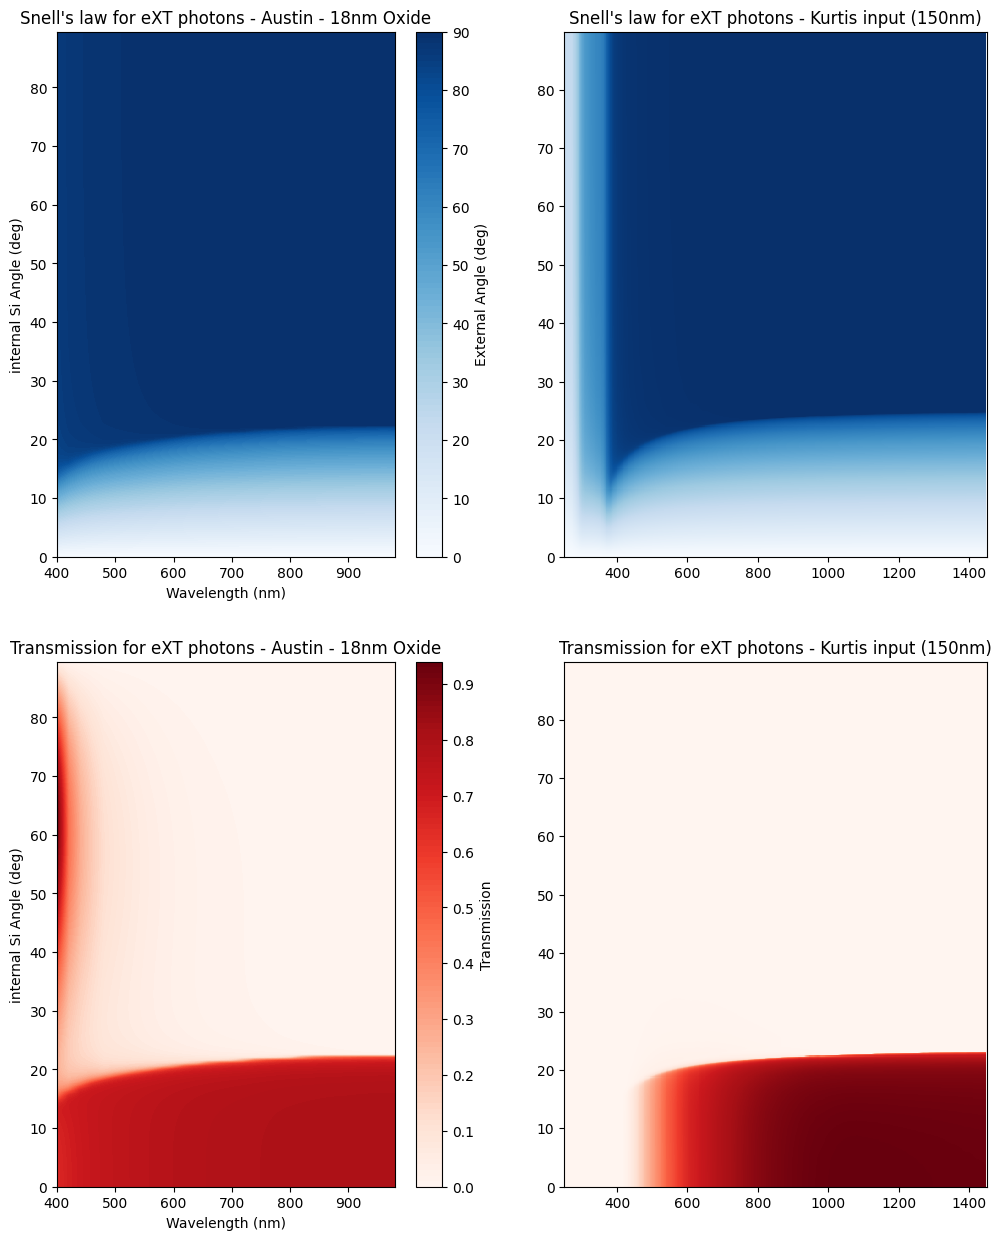

In [13]:
# now plot the LXe vals
fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, figsize=(12, 15))

c1 = ax1.contourf(X, Y, Z_snells_LXe, levels = 100, cmap='Blues')
ax1.set_title("Snell's law for eXT photons - Austin - 18nm Oxide")
ax1.set_xlabel("Wavelength (nm)")
ax1.set_ylabel("internal Si Angle (deg)")
fig.colorbar(c1, label='External Angle (deg)', ax=ax1)

c2 = ax2.contourf(X, Y, Z_trans_LXe, levels=100, cmap='Reds')
ax2.set_title("Transmission for eXT photons - Austin - 18nm Oxide")
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("internal Si Angle (deg)")
fig.colorbar(c2, label='Transmission', ax=ax2)

import uproot
file = uproot.open("/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/eXT_andToyModels_nb/HPK_140nm_Production_And_Transmission_highd.root")
h2_snells = file["AngleConv"]
h2_trans = file["SiO2Trans"]

xSnell = h2_snells.axis('x').edges()
ySnell = h2_snells.axis('y').edges()
binSnell = h2_snells.values()
ax3.pcolormesh(xSnell*1e3, ySnell, binSnell.T, cmap='Blues')
ax3.set_title("Snell's law for eXT photons - Kurtis input (150nm)")

xTrans = h2_trans.axis('x').edges()
yTrans = h2_trans.axis('y').edges()
binTrans = h2_trans.values()
ax4.pcolormesh(xTrans*1e3, yTrans, binTrans.T, cmap='Reds')
ax4.set_title("Transmission for eXT photons - Kurtis input (150nm)")

# y_edges = h2_snells.edges[1]
# bin_contents = h2_snells.values()

# ax3.pcolormesh(x_edges, y_edges, bin_contents.T, cmap='Blues')

[12, 22, 27]


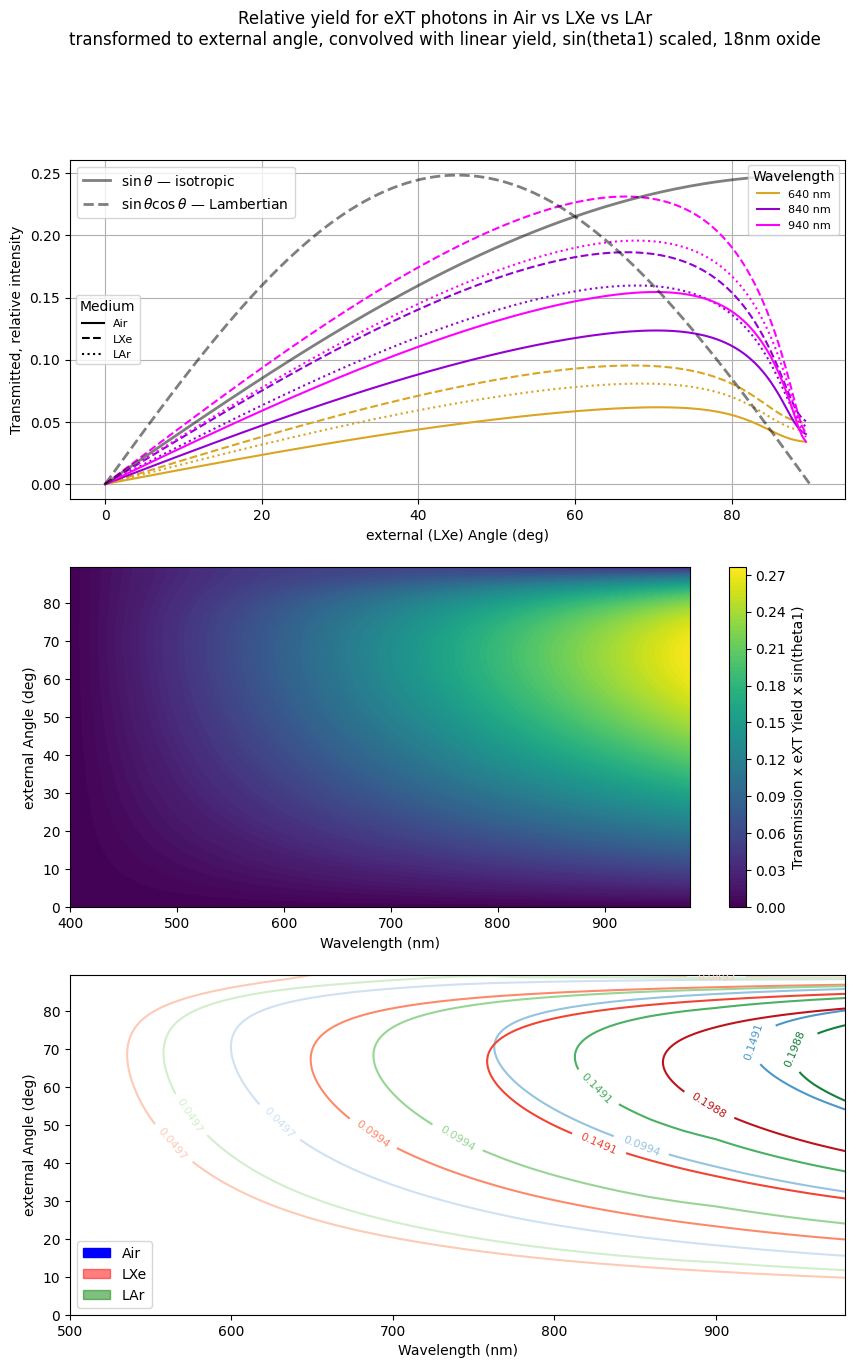

In [23]:
wlensToSlice = [650, 850, 950]
ms.ResetColorCycle()
# print(len(theta1_vals))
# print(len(Y))
# print(Y)
# print(len(X))
# print(X)
# print(Y-theta1_vals)

indicesOfWlens = [np.argmin(np.abs(X[0, :] - angle)) for angle in wlensToSlice]
print(indicesOfWlens)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15))

wlen_colors = []
for ind in indicesOfWlens:
    # print(X[0, ind])    
    # Zslice = Z_transAndConvolved[:, ind] # slice vertically (fixed wavelength)
    # Zslice_lxe = Z_trans_and_sinTheta_LXe[:, ind]

    Yangles = Y[:, ind]
    # ax1.plot(Yangles, Zslice, color = ms.GetNextColor(), label=f"{X[0, ind]} nm")
    # ax1.plot(Yangles, Zslice_lxe, linestyle ="--", color = ms.GetNextColor(1), label=f"{X[0, ind]} nm, LXe")
    
    ZsliceScaled = Z_trans_and_sinTheta[:, ind] # slice vertically (fixed wavelength)
    ZsliceScaled_LXe = Z_trans_and_sinTheta_LXe[:, ind]
    ZsliceScaled_LAr = Z_trans_and_sinTheta_LAr[:, ind]
    
    col = ms.GetNextColor()
    wlen_colors.append(col)
    ax1.plot(Yangles, ZsliceScaled, linestyle ="-", color = col)
    ax1.plot(Yangles, ZsliceScaled_LXe, linestyle ="--", color = col)
    ax1.plot(Yangles, ZsliceScaled_LAr, linestyle =":", color = col)

# ax1.set_xlim(40, 60)
ax1.set_xlabel("external (LXe) Angle (deg)")
ax1.set_ylabel("Transmitted, relative intensity")
ax1.grid()

# Legend 1: wavelength (color)
from matplotlib.lines import Line2D
wlen_handles = [Line2D([0],[0], color=wlen_colors[i], ls='-', label=f"{int(X[0, ind])} nm")
                for i, ind in enumerate(indicesOfWlens)]
leg1 = ax1.legend(handles=wlen_handles, loc='upper right', fontsize=8, title='Wavelength')

# Legend 2: medium (linestyle)
style_handles = [Line2D([0],[0], color='k', ls='-',  label='Air'),
                 Line2D([0],[0], color='k', ls='--', label='LXe'),
                 Line2D([0],[0], color='k', ls=':',  label='LAr')]
leg2 = ax1.legend(handles=style_handles, loc='center left', fontsize=8, title='Medium')

# generic angular distributions for reference
theta_ref = np.linspace(0, 90, 200)
sin_ref = np.sin(theta_ref / rad2deg)
sincos_ref = np.sin(theta_ref / rad2deg) * np.cos(theta_ref / rad2deg)
# normalize to peak of data for visual comparison
peak = np.real(maxZ)
ax1.plot(theta_ref, peak * sin_ref / sin_ref.max(), 'k-', alpha=0.5, lw=2)
ax1.plot(theta_ref, peak * sincos_ref / sincos_ref.max(), 'k--', alpha=0.5, lw=2)

# Legend 3: reference curves
ref_handles = [Line2D([0],[0], color='k', ls='-',  alpha=0.5, lw=2, label=r'$\sin\theta$ — isotropic'),
               Line2D([0],[0], color='k', ls='--', alpha=0.5, lw=2, label=r'$\sin\theta\cos\theta$ — Lambertian')]
leg3 = ax1.legend(handles=ref_handles, loc='upper left', fontsize=10)
ax1.add_artist(leg1)
ax1.add_artist(leg2)

maxZ = max([max(Z_trans_and_sinTheta.flatten()), max(Z_trans_and_sinTheta_LXe.flatten()), max(Z_trans_and_sinTheta_LAr.flatten())])

##

c6 = ax2.contourf(X, Y, 1.1*Z_trans_and_sinTheta_LXe, levels = 100, cmap='viridis')
fig.colorbar(c6, label='Transmission x eXT Yield x sin(theta1)', ax=ax2)

zlevels = np.linspace(0, maxZ, 6)
c5 = ax3.contour(X, Y, Z_trans_and_sinTheta, levels = zlevels, cmap='Blues')
ax3.clabel(c5, inline=True, fontsize=8)

c6_line = ax3.contour(X, Y, Z_trans_and_sinTheta_LXe, levels = zlevels, cmap='Reds')
ax3.clabel(c6_line, inline=True, fontsize=8)

c7 = ax3.contour(X, Y, Z_trans_and_sinTheta_LAr, levels = zlevels, cmap='Greens')
ax3.clabel(c7, inline=True, fontsize=8)

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='Air')
red_patch = mpatches.Patch(color='red', alpha=0.5, label='LXe')
green_patch = mpatches.Patch(color='green', alpha=0.5, label='LAr')
ax3.legend(handles=[blue_patch, red_patch, green_patch], loc='lower left')

ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("external Angle (deg)")

ax3.set_xlim(500, ax3.get_xlim()[1])
ax3.set_xlabel("Wavelength (nm)")
ax3.set_ylabel("external Angle (deg)")

fig.suptitle("Relative yield for eXT photons in Air vs LXe vs LAr\ntransformed to external angle, convolved with linear yield, sin(theta1) scaled, 18nm oxide")

plt.show()

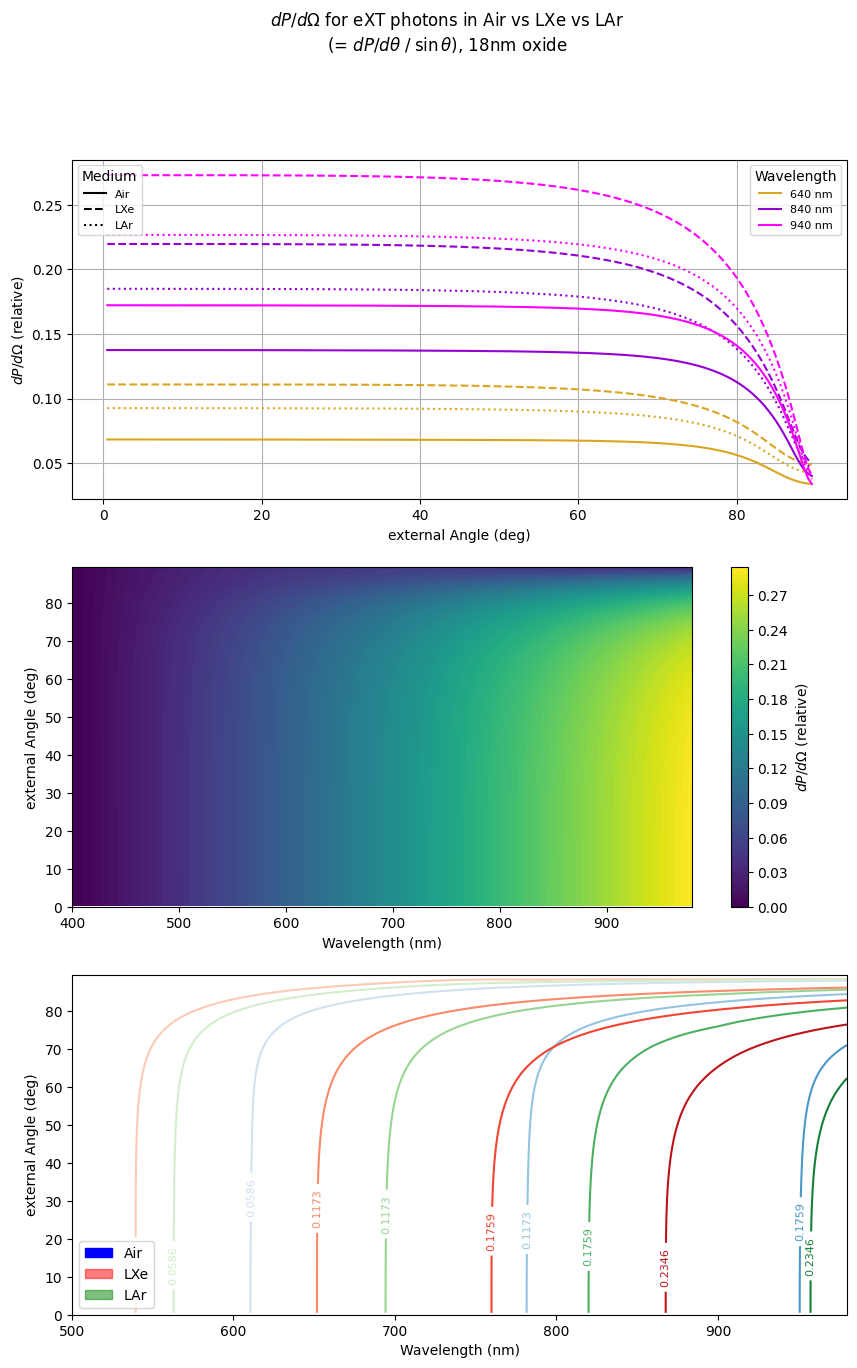

In [16]:
## Same 3 plots but dP/dOmega = (dP/dtheta) / sin(theta)
## i.e. divide by sin(external angle) to remove solid angle Jacobian

sinY = np.sin(Y / rad2deg)
sinY[sinY < 1e-10] = np.nan  # avoid division by zero at theta=0

Z_dOmega_air = np.real(Z_trans_and_sinTheta) / sinY
Z_dOmega_lxe = np.real(Z_trans_and_sinTheta_LXe) / sinY
Z_dOmega_lar = np.real(Z_trans_and_sinTheta_LAr) / sinY

ms.ResetColorCycle()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15))

## --- ax1: wavelength slices ---
wlen_colors_dO = []
for ind in indicesOfWlens:
    Yangles = Y[:, ind]
    
    col = ms.GetNextColor()
    wlen_colors_dO.append(col)
    ax1.plot(Yangles, Z_dOmega_air[:, ind], linestyle="-", color=col)
    ax1.plot(Yangles, Z_dOmega_lxe[:, ind], linestyle="--", color=col)
    ax1.plot(Yangles, Z_dOmega_lar[:, ind], linestyle=":", color=col)

ax1.set_xlabel("external Angle (deg)")
ax1.set_ylabel(r"$dP/d\Omega$ (relative)")
ax1.grid()

from matplotlib.lines import Line2D
wlen_handles = [Line2D([0],[0], color=wlen_colors_dO[i], ls='-', label=f"{int(X[0, ind])} nm")
                for i, ind in enumerate(indicesOfWlens)]
leg1 = ax1.legend(handles=wlen_handles, loc='upper right', fontsize=8, title='Wavelength')

style_handles = [Line2D([0],[0], color='k', ls='-',  label='Air'),
                 Line2D([0],[0], color='k', ls='--', label='LXe'),
                 Line2D([0],[0], color='k', ls=':',  label='LAr')]
ax1.add_artist(leg1)
ax1.legend(handles=style_handles, loc='upper left', fontsize=8, title='Medium')

## --- ax2: LXe filled contour ---
maxZ_dO = np.nanmax([np.nanmax(Z_dOmega_air), np.nanmax(Z_dOmega_lxe), np.nanmax(Z_dOmega_lar)])

c6 = ax2.contourf(X, Y, Z_dOmega_lxe, levels=100, cmap='viridis')
fig.colorbar(c6, label=r'$dP/d\Omega$ (relative)', ax=ax2)

## --- ax3: Air / LXe / LAr contour overlay ---
zlevels_dO = np.linspace(0, maxZ_dO, 6)
c5 = ax3.contour(X, Y, Z_dOmega_air, levels=zlevels_dO, cmap='Blues')
ax3.clabel(c5, inline=True, fontsize=8)

c6_line = ax3.contour(X, Y, Z_dOmega_lxe, levels=zlevels_dO, cmap='Reds')
ax3.clabel(c6_line, inline=True, fontsize=8)

c7 = ax3.contour(X, Y, Z_dOmega_lar, levels=zlevels_dO, cmap='Greens')
ax3.clabel(c7, inline=True, fontsize=8)

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='Air')
red_patch = mpatches.Patch(color='red', alpha=0.5, label='LXe')
green_patch = mpatches.Patch(color='green', alpha=0.5, label='LAr')
ax3.legend(handles=[blue_patch, red_patch, green_patch], loc='lower left')

ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("external Angle (deg)")

ax3.set_xlim(500, ax3.get_xlim()[1])
ax3.set_xlabel("Wavelength (nm)")
ax3.set_ylabel("external Angle (deg)")

fig.suptitle(r"$dP/d\Omega$ for eXT photons in Air vs LXe vs LAr" + "\n"
             r"(= $dP/d\theta \;/\; \sin\theta$), 18nm oxide")

plt.show()

---
Solid Angle explanation

$$\theta$$